In [2]:
import pandas as pd

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../fe_outcomes2.csv",
    encoding="utf-16"
)

print("Dataset shape:", df.shape)
print("\nStatus values:")
print(df["status"].value_counts().sort_index())

print("\nStatus unique values:")
print(sorted(df["status"].unique()))

Dataset shape: (59802, 56)

Status values:
status
0.000000     3487
0.333333     1518
0.666667      442
1.000000    54355
Name: count, dtype: int64

Status unique values:
[np.float64(0.0), np.float64(0.3333333333333332), np.float64(0.6666666666666665), np.float64(1.0)]


In [2]:
df.groupby("status").agg(
    count=("status", "size"),
    avg_funding=("funding_total_usd", "mean"),
    avg_rounds=("funding_rounds", "mean"),
    avg_relationships=("relationships", "mean"),
    avg_milestones=("milestones", "mean")
).round(3)

,count,avg_funding,avg_rounds,avg_relationships,avg_milestones
status,,,,,
0.000000,3487,0.143,0.128,0.004,0.088
0.333333,1518,0.097,0.118,0.002,0.050
0.666667,442,0.150,0.076,0.029,0.167
1.000000,54355,0.080,0.063,0.002,0.027


In [3]:
import matplotlib.pyplot as plt

status_summary = df.groupby("status").agg(
    count=("status", "size"),
    avg_funding=("funding_total_usd", "mean"),
    avg_rounds=("funding_rounds", "mean"),
    avg_relationships=("relationships", "mean"),
    avg_milestones=("milestones", "mean")
).round(3)

status_summary

,count,avg_funding,avg_rounds,avg_relationships,avg_milestones
status,,,,,
0.000000,3487,0.143,0.128,0.004,0.088
0.333333,1518,0.097,0.118,0.002,0.050
0.666667,442,0.150,0.076,0.029,0.167
1.000000,54355,0.080,0.063,0.002,0.027


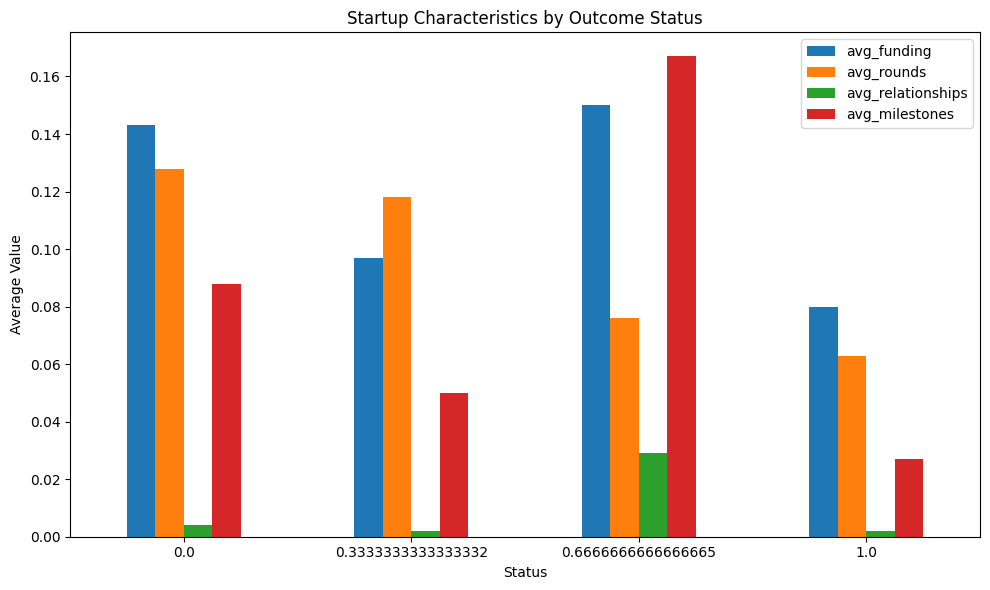

In [4]:
status_summary[[
    "avg_funding",
    "avg_rounds",
    "avg_relationships",
    "avg_milestones"
]].plot(kind="bar", figsize=(10, 6))

plt.title("Startup Characteristics by Outcome Status")
plt.xlabel("Status")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
numeric_corr = df.corr(numeric_only=True)["status"].sort_values(
    ascending=False
)

numeric_corr

status                               1.000000
closed_at_year                       0.978173
isClosed                             0.978173
active_days                          0.977405
last_funding_at                      0.270242
last_funding_at_year                 0.265331
first_funding_at_year                0.258889
first_funding_at                     0.257534
founded_at                           0.190173
first_milestone_at                   0.130263
founded_at_year                      0.123064
first_milestone_at_year              0.099777
lng                                  0.097254
last_milestone_at                    0.073291
country_code_reduced_Other           0.064020
country_code_reduced_IND             0.055963
last_milestone_at_year               0.052555
category_code_reduced_other          0.043472
category_code_reduced_consulting     0.042537
category_code_reduced_ecommerce      0.036201
country_code_reduced_ESP             0.021185
country_code_reduced_GBR          

In [6]:
print("Top positive relationships:")
print(numeric_corr.head(10))

print("\nTop negative relationships:")
print(numeric_corr.tail(10))

Top positive relationships:
status                   1.000000
closed_at_year           0.978173
isClosed                 0.978173
active_days              0.977405
last_funding_at          0.270242
last_funding_at_year     0.265331
first_funding_at_year    0.258889
first_funding_at         0.257534
founded_at               0.190173
first_milestone_at       0.130263
Name: status, dtype: float64

Top negative relationships:
funding_std           -0.121678
funding_total_usd     -0.121678
relationships_log     -0.148786
milestones_log        -0.171123
milestones            -0.175193
PC2                   -0.178809
PC1                   -0.831214
founded_year                NaN
founded_year_std            NaN
founded_year_maxabs         NaN
Name: status, dtype: float64


In [7]:
suspicious_columns = [
    "closed_at_year",
    "isClosed",
    "active_days",
    "last_funding_at",
    "last_milestone_at",
    "first_funding_at",
    "first_milestone_at"
]

existing_suspicious = [
    col for col in suspicious_columns
    if col in df.columns
]

df[existing_suspicious + ["status"]].corr()["status"].sort_values(
    ascending=False
)

status                1.000000
closed_at_year        0.978173
isClosed              0.978173
active_days           0.977405
last_funding_at       0.270242
first_funding_at      0.257534
first_milestone_at    0.130263
last_milestone_at     0.073291
Name: status, dtype: float64

In [8]:
# Features available for prediction
candidate_features = [
    "founded_at",
    "first_funding_at",
    "funding_rounds",
    "funding_total_usd",
    "first_milestone_at",
    "milestones",
    "relationships",
    "lat",
    "lng",
    "founded_at_year",
    "first_funding_at_year",
    "first_milestone_at_year",
    "category_code_reduced_Other",
    "category_code_reduced_advertising",
    "category_code_reduced_biotech",
    "category_code_reduced_consulting",
    "category_code_reduced_ecommerce",
    "category_code_reduced_enterprise",
    "category_code_reduced_games_video",
    "category_code_reduced_mobile",
    "category_code_reduced_other",
    "category_code_reduced_software",
    "category_code_reduced_web",
    "country_code_reduced_AUS",
    "country_code_reduced_CAN",
    "country_code_reduced_DEU",
    "country_code_reduced_ESP",
    "country_code_reduced_FRA",
    "country_code_reduced_GBR",
    "country_code_reduced_IND",
    "country_code_reduced_ISR",
    "country_code_reduced_NLD",
    "country_code_reduced_Other",
    "country_code_reduced_USA"
]

# Keep only columns that actually exist
features = [col for col in candidate_features if col in df.columns]

X = df[features].copy()
y = df["status"].copy()

print("Number of features:", len(features))
print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeatures:")
print(features)

Number of features: 34
X shape: (59802, 34)
y shape: (59802,)

Features:
['founded_at', 'first_funding_at', 'funding_rounds', 'funding_total_usd', 'first_milestone_at', 'milestones', 'relationships', 'lat', 'lng', 'founded_at_year', 'first_funding_at_year', 'first_milestone_at_year', 'category_code_reduced_Other', 'category_code_reduced_advertising', 'category_code_reduced_biotech', 'category_code_reduced_consulting', 'category_code_reduced_ecommerce', 'category_code_reduced_enterprise', 'category_code_reduced_games_video', 'category_code_reduced_mobile', 'category_code_reduced_other', 'category_code_reduced_software', 'category_code_reduced_web', 'country_code_reduced_AUS', 'country_code_reduced_CAN', 'country_code_reduced_DEU', 'country_code_reduced_ESP', 'country_code_reduced_FRA', 'country_code_reduced_GBR', 'country_code_reduced_IND', 'country_code_reduced_ISR', 'country_code_reduced_NLD', 'country_code_reduced_Other', 'country_code_reduced_USA']


In [9]:
print("Target distribution:")
print(y.value_counts().sort_index())

print("\nTarget percentages:")
print(
    (y.value_counts(normalize=True).sort_index() * 100).round(2)
)

Target distribution:
status
0.000000     3487
0.333333     1518
0.666667      442
1.000000    54355
Name: count, dtype: int64

Target percentages:
status
0.000000     5.83
0.333333     2.54
0.666667     0.74
1.000000    90.89
Name: proportion, dtype: float64


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training set: (47841, 34)
Test set: (11961, 34)

Training target distribution:
status
0.000000    0.058
0.333333    0.025
0.666667    0.007
1.000000    0.909
Name: proportion, dtype: float64

Test target distribution:
status
0.000000    0.058
0.333333    0.025
0.666667    0.007
1.000000    0.909
Name: proportion, dtype: float64


In [11]:
from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

ValueError: Unknown label type: continuous. Maybe you are trying to fit a classifier, which expects discrete classes on a regression target with continuous values.

In [12]:
import sys
print(sys.executable)

c:\Users\saivy\AppData\Local\Programs\Python\Python313\python.exe


In [1]:
import sys
print(sys.executable)

c:\Users\saivy\AppData\Local\Programs\Python\Python313\python.exe


In [2]:
import sys
print(sys.executable)

c:\Users\saivy\OneDrive\Documents\MLproj\Predicting-Startup-Acquisition-Machine-Learning-Pipeline\venv\Scripts\python.exe


In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print("Environment ready!")

Environment ready!


In [4]:
df = pd.read_csv(
    "../fe_outcomes2.csv",
    encoding="utf-16"
)

print("Dataset shape:", df.shape)

Dataset shape: (59802, 56)


In [5]:
df["status_class"] = (
    df["status"] * 3
).round().astype(int)

print(df["status_class"].value_counts().sort_index())

status_class
0     3487
1     1518
2      442
3    54355
Name: count, dtype: int64


In [6]:
candidate_features = [
    "founded_at",
    "first_funding_at",
    "funding_rounds",
    "funding_total_usd",
    "first_milestone_at",
    "milestones",
    "relationships",
    "lat",
    "lng",
    "founded_at_year",
    "first_funding_at_year",
    "first_milestone_at_year",
    "category_code_reduced_Other",
    "category_code_reduced_advertising",
    "category_code_reduced_biotech",
    "category_code_reduced_consulting",
    "category_code_reduced_ecommerce",
    "category_code_reduced_enterprise",
    "category_code_reduced_games_video",
    "category_code_reduced_mobile",
    "category_code_reduced_other",
    "category_code_reduced_software",
    "category_code_reduced_web",
    "country_code_reduced_AUS",
    "country_code_reduced_CAN",
    "country_code_reduced_DEU",
    "country_code_reduced_ESP",
    "country_code_reduced_FRA",
    "country_code_reduced_GBR",
    "country_code_reduced_IND",
    "country_code_reduced_ISR",
    "country_code_reduced_NLD",
    "country_code_reduced_Other",
    "country_code_reduced_USA"
]

features = [
    col for col in candidate_features
    if col in df.columns
]

X = df[features].copy()
y = df["status_class"].copy()

print("X:", X.shape)
print("y:", y.shape)

X: (59802, 34)
y: (59802,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (47841, 34)
Testing: (11961, 34)


In [8]:
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [9]:
print(classification_report(
    y_test,
    baseline_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.41      0.05      0.09       697
           1       0.36      0.01      0.03       304
           2       0.60      0.10      0.17        88
           3       0.91      1.00      0.95     10872

    accuracy                           0.91     11961
   macro avg       0.57      0.29      0.31     11961
weighted avg       0.87      0.91      0.87     11961



In [10]:
print("Accuracy:",
      accuracy_score(y_test, baseline_pred))

print("Macro F1:",
      f1_score(
          y_test,
          baseline_pred,
          average="macro",
          zero_division=0
      ))

Accuracy: 0.9083688654794749
Macro F1: 0.30986367489222344


In [11]:
print(classification_report(
    y_test,
    baseline_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.41      0.05      0.09       697
           1       0.36      0.01      0.03       304
           2       0.60      0.10      0.17        88
           3       0.91      1.00      0.95     10872

    accuracy                           0.91     11961
   macro avg       0.57      0.29      0.31     11961
weighted avg       0.87      0.91      0.87     11961



In [12]:
print(confusion_matrix(
    y_test,
    baseline_pred
))

[[   34     2     1   660]
 [    4     4     0   296]
 [    1     0     9    78]
 [   44     5     5 10818]]


In [13]:
print(confusion_matrix(
    y_test,
    baseline_pred
))

[[   34     2     1   660]
 [    4     4     0   296]
 [    1     0     9    78]
 [   44     5     5 10818]]


In [14]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts().sort_index())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts().sort_index())

Before SMOTE:
status_class
0     2790
1     1214
2      354
3    43483
Name: count, dtype: int64

After SMOTE:
status_class
0    43483
1    43483
2    43483
3    43483
Name: count, dtype: int64


In [15]:
smote_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

smote_lr.fit(X_train_smote, y_train_smote)

smote_lr_pred = smote_lr.predict(X_test)

In [17]:
smote_lr_accuracy = accuracy_score(
    y_test,
    smote_lr_pred
)

smote_lr_f1 = f1_score(
    y_test,
    smote_lr_pred,
    average="macro",
    zero_division=0
)

print("Logistic Regression + SMOTE")
print("---------------------------")
print("Accuracy:", smote_lr_accuracy)
print("Macro F1:", smote_lr_f1)

print(classification_report(
    y_test,
    smote_lr_pred,
    zero_division=0
))

Logistic Regression + SMOTE
---------------------------
Accuracy: 0.6578881364434411
Macro F1: 0.34055941175318477
              precision    recall  f1-score   support

           0       0.15      0.47      0.22       697
           1       0.12      0.62      0.21       304
           2       0.08      0.64      0.14        88
           3       0.97      0.67      0.79     10872

    accuracy                           0.66     11961
   macro avg       0.33      0.60      0.34     11961
weighted avg       0.90      0.66      0.74     11961



In [18]:
from sklearn.ensemble import RandomForestClassifier

rf_smote = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_smote.fit(X_train_smote, y_train_smote)

rf_smote_pred = rf_smote.predict(X_test)

print("Random Forest + SMOTE trained!")

Random Forest + SMOTE trained!


In [19]:
rf_accuracy = accuracy_score(
    y_test,
    rf_smote_pred
)

rf_f1 = f1_score(
    y_test,
    rf_smote_pred,
    average="macro",
    zero_division=0
)

print("Random Forest + SMOTE")
print("--------------------")
print("Accuracy:", rf_accuracy)
print("Macro F1:", rf_f1)

Random Forest + SMOTE
--------------------
Accuracy: 0.8753448708301982
Macro F1: 0.4451694580194586


In [21]:
from sklearn.ensemble import ExtraTreesClassifier

et_smote = ExtraTreesClassifier(
    n_estimators=50,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=2
)

et_smote.fit(X_train_smote, y_train_smote)

et_smote_pred = et_smote.predict(X_test)

print("Extra Trees + SMOTE trained successfully!")

Extra Trees + SMOTE trained successfully!


In [3]:
df = pd.read_csv(
    "../fe_outcomes2.csv",
    encoding="utf-16"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (59802, 56)


In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from imblearn.over_sampling import SMOTE

print("Imports ready")

Imports ready


In [3]:
df = pd.read_csv(
    "../fe_outcomes2.csv",
    encoding="utf-16"
)

df["status_class"] = (
    df["status"] * 3
).round().astype(int)

df = df.drop_duplicates().copy()

print("Dataset:", df.shape)

Dataset: (59769, 57)


In [4]:
candidate_features = [
    "founded_at",
    "first_funding_at",
    "funding_rounds",
    "funding_total_usd",
    "first_milestone_at",
    "milestones",
    "relationships",
    "lat",
    "lng",
    "founded_at_year",
    "first_funding_at_year",
    "first_milestone_at_year",
    "category_code_reduced_Other",
    "category_code_reduced_advertising",
    "category_code_reduced_biotech",
    "category_code_reduced_consulting",
    "category_code_reduced_ecommerce",
    "category_code_reduced_enterprise",
    "category_code_reduced_games_video",
    "category_code_reduced_mobile",
    "category_code_reduced_other",
    "category_code_reduced_software",
    "category_code_reduced_web",
    "country_code_reduced_AUS",
    "country_code_reduced_CAN",
    "country_code_reduced_DEU",
    "country_code_reduced_ESP",
    "country_code_reduced_FRA",
    "country_code_reduced_GBR",
    "country_code_reduced_IND",
    "country_code_reduced_ISR",
    "country_code_reduced_NLD",
    "country_code_reduced_Other",
    "country_code_reduced_USA"
]

features = [
    col for col in candidate_features
    if col in df.columns
]

X = df[features].copy()
y = df["status_class"].copy()

print("X:", X.shape)
print("y:", y.shape)

X: (59769, 34)
y: (59769,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (47815, 34)
Test: (11954, 34)


In [6]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("SMOTE training data:", X_train_smote.shape)
print(y_train_smote.value_counts().sort_index())

SMOTE training data: (173828, 34)
status_class
0    43457
1    43457
2    43457
3    43457
Name: count, dtype: int64


In [7]:
et_smote = ExtraTreesClassifier(
    n_estimators=50,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=2
)

et_smote.fit(X_train_smote, y_train_smote)

et_smote_pred = et_smote.predict(X_test)

print("Extra Trees + SMOTE trained successfully!")

Extra Trees + SMOTE trained successfully!


In [8]:
et_accuracy = accuracy_score(y_test, et_smote_pred)

et_f1 = f1_score(
    y_test,
    et_smote_pred,
    average="macro",
    zero_division=0
)

print("Extra Trees + SMOTE")
print("------------------")
print("Accuracy:", et_accuracy)
print("Macro F1:", et_f1)

Extra Trees + SMOTE
------------------
Accuracy: 0.7379956499916346
Macro F1: 0.3778579423070135


In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_smote = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=2
)

rf_smote.fit(X_train_smote, y_train_smote)

rf_smote_pred = rf_smote.predict(X_test)

print("Random Forest + SMOTE recreated successfully!")

Random Forest + SMOTE recreated successfully!


In [11]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, rf_smote_pred))

print("Macro F1:", f1_score(
    y_test,
    rf_smote_pred,
    average="macro",
    zero_division=0
))

Accuracy: 0.8729295633260833
Macro F1: 0.4351240541806203


In [12]:
print(classification_report(
    y_test,
    rf_smote_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.30      0.32      0.31       697
           1       0.22      0.23      0.23       304
           2       0.23      0.33      0.27        88
           3       0.94      0.93      0.93     10865

    accuracy                           0.87     11954
   macro avg       0.42      0.45      0.44     11954
weighted avg       0.88      0.87      0.88     11954



In [4]:
import csv

file_path = "../fe_outcomes2.csv"

with open(file_path, "r", encoding="latin1", newline="") as f:
    reader = csv.reader(f)
    header = next(reader)

    print("Number of columns:", len(header))
    print("First 10 columns:", header[:10])

    for i, row in enumerate(reader, start=2):
        if len(row) != len(header):
            print("Problem at row:", i)
            print("Expected columns:", len(header))
            print("Found columns:", len(row))
            print("Row:", row[:10])
            break

Number of columns: 56
First 10 columns: ['ÿþs\x00t\x00a\x00t\x00u\x00s\x00', '\x00f\x00o\x00u\x00n\x00d\x00e\x00d\x00_\x00a\x00t\x00', '\x00f\x00i\x00r\x00s\x00t\x00_\x00f\x00u\x00n\x00d\x00i\x00n\x00g\x00_\x00a\x00t\x00', '\x00l\x00a\x00s\x00t\x00_\x00f\x00u\x00n\x00d\x00i\x00n\x00g\x00_\x00a\x00t\x00', '\x00f\x00u\x00n\x00d\x00i\x00n\x00g\x00_\x00r\x00o\x00u\x00n\x00d\x00s\x00', '\x00f\x00u\x00n\x00d\x00i\x00n\x00g\x00_\x00t\x00o\x00t\x00a\x00l\x00_\x00u\x00s\x00d\x00', '\x00f\x00i\x00r\x00s\x00t\x00_\x00m\x00i\x00l\x00e\x00s\x00t\x00o\x00n\x00e\x00_\x00a\x00t\x00', '\x00l\x00a\x00s\x00t\x00_\x00m\x00i\x00l\x00e\x00s\x00t\x00o\x00n\x00e\x00_\x00a\x00t\x00', '\x00m\x00i\x00l\x00e\x00s\x00t\x00o\x00n\x00e\x00s\x00', '\x00r\x00e\x00l\x00a\x00t\x00i\x00o\x00n\x00s\x00h\x00i\x00p\x00s\x00']
Problem at row: 2
Expected columns: 56
Found columns: 1
Row: ['\x00']


In [5]:
df = pd.read_csv(
    "../fe_outcomes2.csv",
    encoding="utf-16"
)

In [7]:
df = pd.read_csv(
    "../fe_outcomes2.csv",
    encoding="utf-16"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (59802, 56)


In [8]:
df.shape


(59802, 56)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59802 entries, 0 to 59801
Data columns (total 56 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   status                             59802 non-null  float64
 1   founded_at                         59802 non-null  float64
 2   first_funding_at                   59802 non-null  float64
 3   last_funding_at                    59802 non-null  float64
 4   funding_rounds                     59802 non-null  float64
 5   funding_total_usd                  59802 non-null  float64
 6   first_milestone_at                 59802 non-null  float64
 7   last_milestone_at                  59802 non-null  float64
 8   milestones                         59802 non-null  float64
 9   relationships                      59802 non-null  float64
 10  lat                                59802 non-null  float64
 11  lng                                59802 non-null  float64
 12  f

In [4]:
df["status"].value_counts(dropna=False)

status
1.000000    54355
0.000000     3487
0.333333     1518
0.666667      442
Name: count, dtype: int64

In [5]:
df["status_class"] = (df["status"] * 3).round().astype(int)

In [6]:
df["status_class"].value_counts().sort_index()

status_class
0     3487
1     1518
2      442
3    54355
Name: count, dtype: int64

In [7]:
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

Duplicate rows: 33
Total missing values: 0


In [8]:
print("Before:", len(df))

df = df.drop_duplicates().copy()

print("After:", len(df))

Before: 59802
After: 59769


In [9]:
df.dtypes


status                               float64
founded_at                           float64
first_funding_at                     float64
last_funding_at                      float64
funding_rounds                       float64
funding_total_usd                    float64
first_milestone_at                   float64
last_milestone_at                    float64
milestones                           float64
relationships                        float64
lat                                  float64
lng                                  float64
founded_at_year                      float64
first_funding_at_year                float64
closed_at_year                       float64
last_funding_at_year                 float64
first_milestone_at_year              float64
last_milestone_at_year               float64
category_code_reduced_Other             bool
category_code_reduced_advertising       bool
category_code_reduced_biotech           bool
category_code_reduced_consulting        bool
category_c

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
status,59769.0,0.922262,0.253789,0.000000,1.000000e+00,1.000000e+00,1.000000,1.000000
founded_at,59769.0,0.587270,0.264503,0.000000,3.845702e-01,6.442138e-01,0.802232,1.000000
first_funding_at,59769.0,0.883007,0.225794,0.000000,8.727800e-01,1.000000e+00,1.000000,1.000000
last_funding_at,59769.0,0.898527,0.208740,0.000000,9.186805e-01,1.000000e+00,1.000000,1.000000
funding_rounds,59769.0,0.068648,0.212301,0.000000,0.000000e+00,0.000000e+00,0.000000,1.000000
funding_total_usd,59769.0,0.084344,0.122852,0.000000,5.609943e-02,5.609943e-02,0.056099,1.000000
first_milestone_at,59769.0,0.791254,0.267056,0.000000,6.448836e-01,9.263628e-01,1.000000,1.000000
last_milestone_at,59769.0,0.810961,0.256227,0.000000,6.762638e-01,9.521259e-01,1.000000,1.000000
milestones,59769.0,0.032263,0.086675,0.000000,0.000000e+00,0.000000e+00,0.000000,1.000000
relationships,59769.0,0.002037,0.009546,0.000000,8.417508e-04,8.417508e-04,0.001684,1.000000


In [11]:
X = df.drop(columns=["status", "status_class"])
y = df["status_class"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (59769, 55)
Target: (59769,)


In [12]:
print(X.columns.tolist())

['founded_at', 'first_funding_at', 'last_funding_at', 'funding_rounds', 'funding_total_usd', 'first_milestone_at', 'last_milestone_at', 'milestones', 'relationships', 'lat', 'lng', 'founded_at_year', 'first_funding_at_year', 'closed_at_year', 'last_funding_at_year', 'first_milestone_at_year', 'last_milestone_at_year', 'category_code_reduced_Other', 'category_code_reduced_advertising', 'category_code_reduced_biotech', 'category_code_reduced_consulting', 'category_code_reduced_ecommerce', 'category_code_reduced_enterprise', 'category_code_reduced_games_video', 'category_code_reduced_mobile', 'category_code_reduced_other', 'category_code_reduced_software', 'category_code_reduced_web', 'country_code_reduced_AUS', 'country_code_reduced_CAN', 'country_code_reduced_DEU', 'country_code_reduced_ESP', 'country_code_reduced_FRA', 'country_code_reduced_GBR', 'country_code_reduced_IND', 'country_code_reduced_ISR', 'country_code_reduced_NLD', 'country_code_reduced_Other', 'country_code_reduced_USA',

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (47815, 55)
Testing data: (11954, 55)


In [14]:
from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train, y_train)

c:\Users\saivy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [15]:
y_pred = baseline_model.predict(X_test)

In [16]:
from sklearn.metrics import accuracy_score, classification_report

print("Baseline Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Baseline Accuracy: 0.977580726116781

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.91      0.87       697
           1       0.74      0.59      0.66       304
           2       0.62      0.20      0.31        88
           3       0.99      1.00      1.00     10865

    accuracy                           0.98     11954
   macro avg       0.80      0.68      0.71     11954
weighted avg       0.98      0.98      0.98     11954



In [17]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[  636    61     0     0]
 [  126   178     0     0]
 [    0     0    18    70]
 [    0     0    11 10854]]


In [18]:
print("Class distribution in training data:")
print(y_train.value_counts().sort_index())

print("\nClass distribution in test data:")
print(y_test.value_counts().sort_index())

Class distribution in training data:
status_class
0     2790
1     1214
2      354
3    43457
Name: count, dtype: int64

Class distribution in test data:
status_class
0      697
1      304
2       88
3    10865
Name: count, dtype: int64


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Macro Precision:", precision_score(y_test, y_pred, average="macro", zero_division=0))
print("Macro Recall   :", recall_score(y_test, y_pred, average="macro", zero_division=0))
print("Macro F1       :", f1_score(y_test, y_pred, average="macro", zero_division=0))

Accuracy : 0.977580726116781
Macro Precision: 0.7984243224374917
Macro Recall   : 0.6753853527783668
Macro F1       : 0.7078554497612844


In [20]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [21]:
print("Random Forest Results")
print("---------------------")

print("Accuracy:",
      accuracy_score(y_test, rf_pred))

print("Macro Precision:",
      precision_score(y_test, rf_pred, average="macro", zero_division=0))

print("Macro Recall:",
      recall_score(y_test, rf_pred, average="macro", zero_division=0))

print("Macro F1:",
      f1_score(y_test, rf_pred, average="macro", zero_division=0))

Random Forest Results
---------------------
Accuracy: 0.984189392671909
Macro Precision: 0.9117588062369467
Macro Recall: 0.7439060814386681
Macro F1: 0.7875638714858046


In [22]:
print(classification_report(
    y_test,
    rf_pred,
    zero_division=0
))


              precision    recall  f1-score   support

           0       0.89      0.94      0.91       697
           1       0.83      0.73      0.78       304
           2       0.93      0.31      0.46        88
           3       0.99      1.00      1.00     10865

    accuracy                           0.98     11954
   macro avg       0.91      0.74      0.79     11954
weighted avg       0.98      0.98      0.98     11954



In [23]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Macro Recall": [
        recall_score(y_test, y_pred, average="macro", zero_division=0),
        recall_score(y_test, rf_pred, average="macro", zero_division=0)
    ],
    "Macro F1": [
        f1_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test, rf_pred, average="macro", zero_division=0)
    ]
})

results

,Model,Accuracy,Macro Recall,Macro F1
0,Logistic Regression,0.977581,0.675385,0.707855
1,Random Forest,0.984189,0.743906,0.787564


In [24]:
from imblearn.over_sampling import SMOTE

In [ ]:
smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [2]:
print("Before SMOTE:")
print(y_train.value_counts().sort_index())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts().sort_index())

Before SMOTE:


NameError: name 'y_train' is not defined

In [3]:
X_train, X_test, y_train, y_test = train_test_split(...)

NameError: name 'train_test_split' is not defined

In [4]:
import pandas as pd

from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

In [5]:
df = pd.read_csv(
    "../fe_outcomes2.csv",
    encoding="utf-16"
)

df["status_class"] = (df["status"] * 3).round().astype(int)

df = df.drop_duplicates().copy()

print("Dataset:", df.shape)

Dataset: (59769, 57)


In [6]:
X = df.drop(columns=["status", "status_class"])
y = df["status_class"]

print("X:", X.shape)
print("y:", y.shape)

X: (59769, 55)
y: (59769,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (47815, 55)
Testing: (11954, 55)


In [8]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [9]:
print("Before SMOTE:")
print(y_train.value_counts().sort_index())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts().sort_index())

Before SMOTE:
status_class
0     2790
1     1214
2      354
3    43457
Name: count, dtype: int64

After SMOTE:
status_class
0    43457
1    43457
2    43457
3    43457
Name: count, dtype: int64


In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_smote = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_smote.fit(X_train_smote, y_train_smote)

rf_smote_pred = rf_smote.predict(X_test)

print("Random Forest + SMOTE trained successfully!")

Random Forest + SMOTE trained successfully!


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:",
      accuracy_score(y_test, rf_smote_pred))

print("Macro Precision:",
      precision_score(
          y_test,
          rf_smote_pred,
          average="macro",
          zero_division=0
      ))

print("Macro Recall:",
      recall_score(
          y_test,
          rf_smote_pred,
          average="macro",
          zero_division=0
      ))

print("Macro F1:",
      f1_score(
          y_test,
          rf_smote_pred,
          average="macro",
          zero_division=0
      ))

Accuracy: 0.9818470804751548
Macro Precision: 0.7985193006050512
Macro Recall: 0.7892524234298868
Macro F1: 0.7936747874153037


In [12]:
print(classification_report(
    y_test,
    rf_smote_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.91      0.91      0.91       697
           1       0.78      0.79      0.79       304
           2       0.51      0.47      0.49        88
           3       1.00      1.00      1.00     10865

    accuracy                           0.98     11954
   macro avg       0.80      0.79      0.79     11954
weighted avg       0.98      0.98      0.98     11954



In [13]:
cm_rf_smote = confusion_matrix(
    y_test,
    rf_smote_pred
)

print(cm_rf_smote)

[[  631    66     0     0]
 [   64   240     0     0]
 [    0     0    41    47]
 [    0     0    40 10825]]


In [14]:
from sklearn.ensemble import ExtraTreesClassifier

et_smote = ExtraTreesClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

et_smote.fit(X_train_smote, y_train_smote)

et_smote_pred = et_smote.predict(X_test)

print("Extra Trees + SMOTE trained successfully!")

Extra Trees + SMOTE trained successfully!


In [15]:
print("Accuracy:",
      accuracy_score(y_test, et_smote_pred))

print("Macro Precision:",
      precision_score(
          y_test,
          et_smote_pred,
          average="macro",
          zero_division=0
      ))

print("Macro Recall:",
      recall_score(
          y_test,
          et_smote_pred,
          average="macro",
          zero_division=0
      ))

print("Macro F1:",
      f1_score(
          y_test,
          et_smote_pred,
          average="macro",
          zero_division=0
      ))

Accuracy: 0.98034130834867
Macro Precision: 0.7828862227805
Macro Recall: 0.764692758894987
Macro F1: 0.7732088095270679


In [16]:
print(classification_report(
    y_test,
    et_smote_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.89      0.91      0.90       697
           1       0.78      0.75      0.76       304
           2       0.47      0.41      0.44        88
           3       1.00      1.00      1.00     10865

    accuracy                           0.98     11954
   macro avg       0.78      0.76      0.77     11954
weighted avg       0.98      0.98      0.98     11954



In [17]:
results = pd.DataFrame({
    "Model": [
        "Random Forest + SMOTE",
        "Extra Trees + SMOTE"
    ],
    
    "Accuracy": [
        accuracy_score(y_test, rf_smote_pred),
        accuracy_score(y_test, et_smote_pred)
    ],
    
    "Macro Precision": [
        precision_score(y_test, rf_smote_pred, average="macro", zero_division=0),
        precision_score(y_test, et_smote_pred, average="macro", zero_division=0)
    ],
    
    "Macro Recall": [
        recall_score(y_test, rf_smote_pred, average="macro", zero_division=0),
        recall_score(y_test, et_smote_pred, average="macro", zero_division=0)
    ],
    
    "Macro F1": [
        f1_score(y_test, rf_smote_pred, average="macro", zero_division=0),
        f1_score(y_test, et_smote_pred, average="macro", zero_division=0)
    ]
})

results.sort_values("Macro F1", ascending=False)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Random Forest + SMOTE,0.981847,0.798519,0.789252,0.793675
1,Extra Trees + SMOTE,0.980341,0.782886,0.764693,0.773209


In [19]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": et_smote.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
40,active_days,0.140644
13,closed_at_year,0.108470
39,isClosed,0.097867
0,founded_at,0.090287
53,PC1,0.078158
11,founded_at_year,0.039375
43,relationships_log,0.031532
2,last_funding_at,0.025061
54,PC2,0.024667
45,milestones_log,0.024320


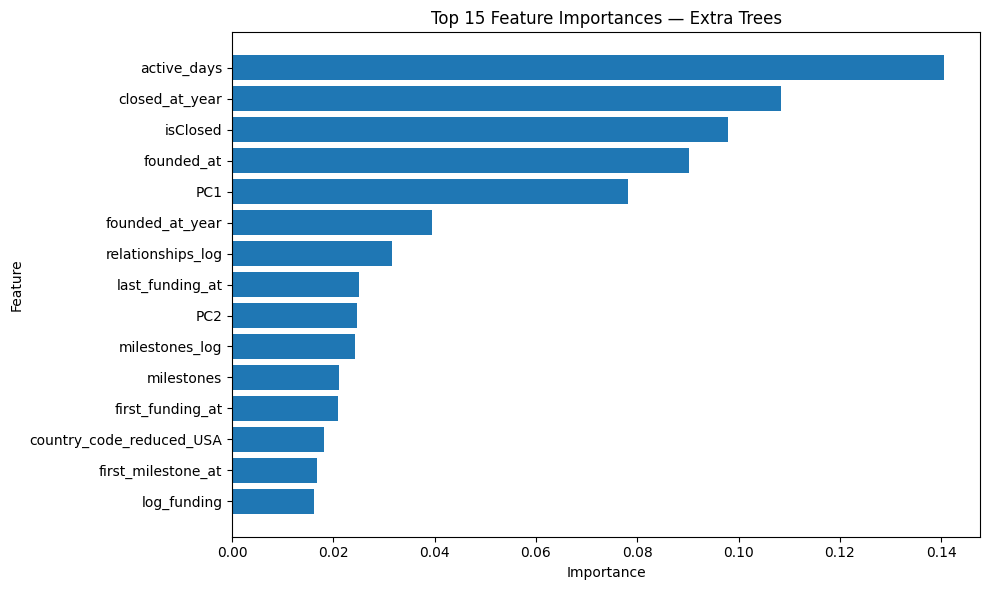

In [20]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances — Extra Trees")
plt.tight_layout()
plt.show()

In [21]:
print(df[["PC1", "PC2"]].describe())

                PC1           PC2
count  59769.000000  59769.000000
mean      -6.075494      0.000156
std        0.000704      1.034404
min       -6.076348     -0.809228
25%       -6.075935     -0.291391
50%       -6.075745     -0.274128
75%       -6.075363     -0.238386
max       -6.071745      7.747538


In [22]:
print(
    "PC1 variance:",
    df["PC1"].var()
)

print(
    "PC2 variance:",
    df["PC2"].var()
)

PC1 variance: 4.960836726862134e-07
PC2 variance: 1.0699914752777309


In [23]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import RandomizedSearchCV

In [24]:
tuning_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", ExtraTreesClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

In [25]:
param_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", None]
}

In [26]:
random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="f1_macro",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [1]:
random_search.fit(X_train, y_train)

NameError: name 'random_search' is not defined

In [3]:
import pandas as pd

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print("All imports successful!")

All imports successful!


In [4]:
# Recreate X and y
X = df.drop(columns=["status", "status_class"])
y = df["status_class"]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

NameError: name 'df' is not defined

In [5]:
# ============================================
# MASTER SETUP — Rebuild project state
# ============================================

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import RandomizedSearchCV


# 1. Load dataset
df = pd.read_csv(
    "../fe_outcomes2.csv",
    encoding="utf-16"
)

print("Original dataset:", df.shape)


# 2. Convert normalized status to actual classes
df["status_class"] = (
    df["status"] * 3
).round().astype(int)


# 3. Remove duplicate rows
before = len(df)

df = df.drop_duplicates().copy()

after = len(df)

print("Duplicates removed:", before - after)
print("Clean dataset:", df.shape)


# 4. Separate features and target
X = df.drop(
    columns=["status", "status_class"]
)

y = df["status_class"]

print("Features:", X.shape)
print("Target:", y.shape)


# 5. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


# 6. Check target distribution
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTest class distribution:")
print(y_test.value_counts().sort_index())


print("\n================================")
print("PROJECT STATE READY")
print("================================")

Original dataset: (59802, 56)
Duplicates removed: 33
Clean dataset: (59769, 57)
Features: (59769, 55)
Target: (59769,)
Training: (47815, 55)
Testing: (11954, 55)

Training class distribution:
status_class
0     2790
1     1214
2      354
3    43457
Name: count, dtype: int64

Test class distribution:
status_class
0      697
1      304
2       88
3    10865
Name: count, dtype: int64

PROJECT STATE READY


In [6]:
tuning_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", ExtraTreesClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

param_distributions = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="f1_macro",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("RandomizedSearchCV is ready!")

RandomizedSearchCV is ready!


In [ ]:
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
